In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取预测结果文件，假设文件名为 'predicted_results.csv'
df = pd.read_csv('final_all_predictions_real_name.csv')
print(df)

            cell      drug  true_ic50  predicted_ic50 cell_name     drug_name
0     ACH-000408   9813758   4.249931        4.393967       TE5    BMS-345541
1     ACH-000493      5394   6.142616        7.114117    SNU423  Temozolomide
2     ACH-000258  44182295  -3.314128       -3.676685    DU4475   Refametinib
3     ACH-000171      5394   9.104477        8.764147   VMRCRCZ  Temozolomide
4     ACH-000401  52913813   2.982357        2.402412   COLO800       AZD8186
...          ...       ...        ...             ...       ...           ...
8142  ACH-000781   9933475   2.575051        2.850926  NCIH2023     Cediranib
8143  ACH-000090   9936746   4.798638        2.642894       PC3        OTX015
8144  ACH-000950  44632017   1.587172        1.874382      LOVO      YK-4-279
8145  ACH-000115  23725625   4.304608        4.559668      VCAP      Olaparib
8146  ACH-000953    992586   3.261803        2.280905     SUPT1        UMI-77

[8147 rows x 6 columns]


Top 10 Sensitive Drugs (IDs):
['Bortezomib', 'Sepantronium bromide', 'Docetaxel', 'Vinblastine', 'Daporinad', 'Elesclomol', 'Dinaciclib', 'Vinorelbine', 'Paclitaxel', 'SN-38']

Top 10 Resistant Drugs (IDs):
['EPZ004777', 'Cyclophosphamide', 'MIRA-1', 'Lenalidomide', 'SB216763', 'PFI3', 'GSK2830371', 'EPZ5676', 'Motesanib', 'Temozolomide']


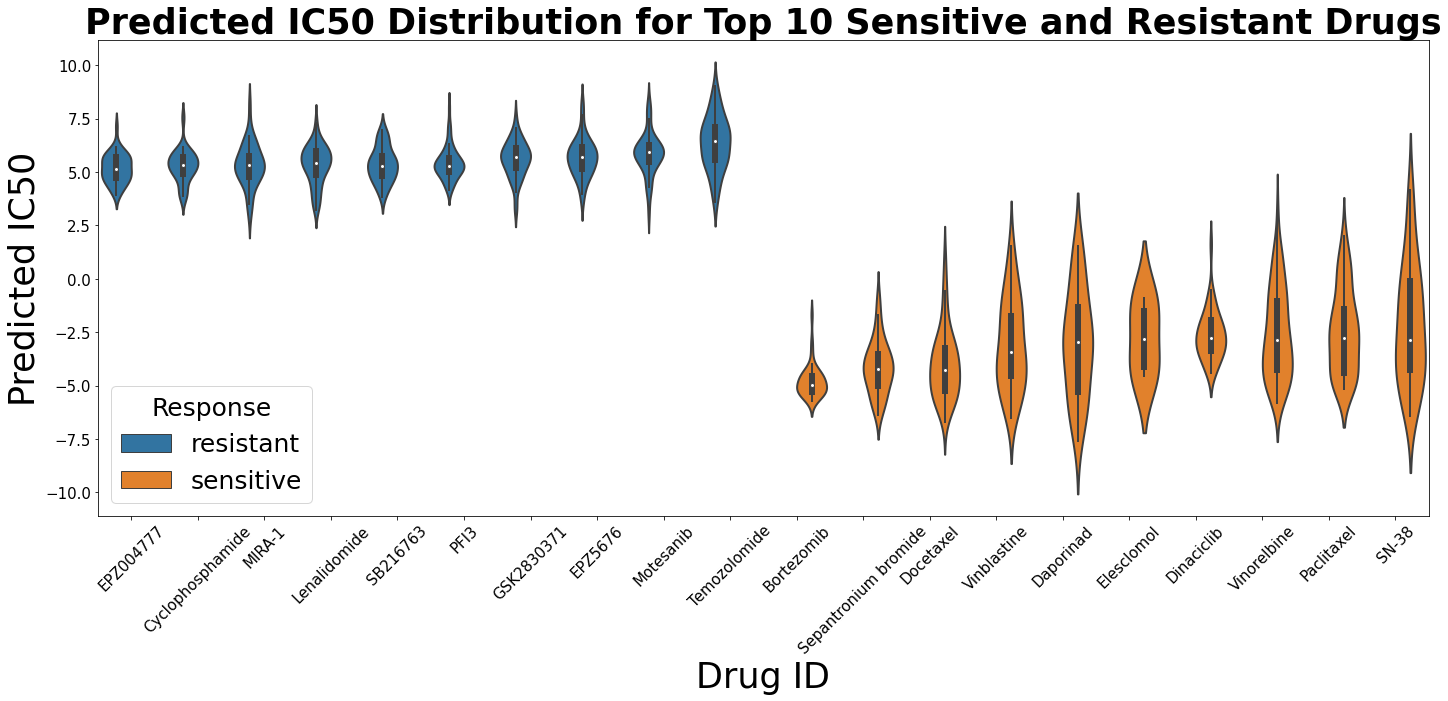

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取预测结果文件，假设文件名为 'final_all_predictions_real_name.csv'
df = pd.read_csv('final_all_predictions_real_name.csv')

# 先计算每个药物的预测IC50均值，用于区分敏感和耐药药物
drug_mean = df.groupby('drug_name')['predicted_ic50'].mean().sort_values()

# 取均值最低的前10个药物作为“sensitive”，均值最高的前10个作为“resistant”
top10_sensitive = drug_mean.head(10).index.tolist()
top10_resistant = drug_mean.tail(10).index.tolist()

# 打印药物ID，看看哪些药物ID被选为敏感和耐药药物
print("Top 10 Sensitive Drugs (IDs):")
print(drug_mean.head(10).index.tolist())

print("\nTop 10 Resistant Drugs (IDs):")
print(drug_mean.tail(10).index.tolist())

# 标记每条记录对应的响应类别
def classify_response(drug):
    if drug in top10_sensitive:
        return 'sensitive'
    elif drug in top10_resistant:
        return 'resistant'
    else:
        return 'other'

df['response'] = df['drug_name'].apply(classify_response)

# 过滤掉“other”类别，只保留sensitive和resistant
plot_df = df[df['response'] != 'other']

# 设置药物显示顺序，左边是抗性药物，右边是敏感药物
order = top10_resistant + top10_sensitive  # 把耐药药物放左边，敏感药物放右边

# 增大图形尺寸
plt.figure(figsize=(22, 12))  # 更宽的画布尺寸

# 画小提琴图，并且在小提琴内部加入箱线图
sns.violinplot(x='drug_name', y='predicted_ic50', hue='response', data=plot_df, 
               inner='box', order=order, linewidth=2, width=0.9)  # 调整小提琴宽度，增加显示空间

# 设置X轴标签旋转和标题
plt.xticks(rotation=45, fontsize=15)
plt.yticks(fontsize=15)
plt.title('Predicted IC50 Distribution for Top 10 Sensitive and Resistant Drugs', fontsize=35, weight='bold')
plt.xlabel('Drug ID', fontsize=35)
plt.ylabel('Predicted IC50', fontsize=35)

# 自动调整布局
plt.tight_layout()

# 调整边距，确保不被裁剪
plt.subplots_adjust(left=0.08, right=0.92, top=0.9, bottom=0.35)

# 设置图例位置到左下角，并增加字体大小
plt.legend(title='Response', loc='lower left', fontsize=25, title_fontsize=25)

# 保存为高分辨率 TIF 格式图片
plt.savefig('picture/1.19aml_drug_response_violin_full.tiff', dpi=400)

# 显示图像
plt.show()


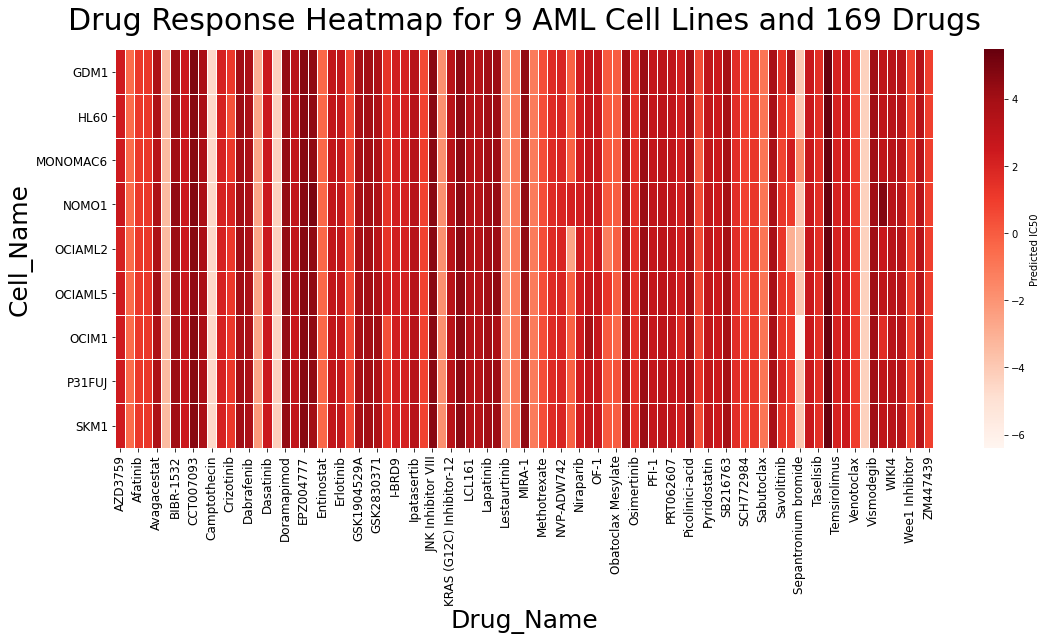

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 预测结果文件路径
pred_csv_path = 'final_all_predictions_real_name.csv'

# 9种AML细胞系ID列表（根据实际情况替换）
aml_cell_lines = [
    'HL60', 'MONOMAC6', 'OCIAML5', 'GDM1', 'OCIAML2',
    'NOMO1', 'SKM1', 'OCIM1', 'P31FUJ'  # 基于你提供的图像中的AML细胞系名称
]

# 读取预测结果
df = pd.read_csv(pred_csv_path)

# 只筛选AML细胞系的数据
aml_df = df[df['cell_name'].isin(aml_cell_lines)]

# 创建一个透视表：行是细胞系，列是药物，值是IC50
heatmap_data = aml_df.pivot_table(index='cell_name', columns='drug_name', values='predicted_ic50', aggfunc='mean')

# 使用每列的均值填充缺失值
heatmap_data_filled = heatmap_data.apply(lambda x: x.fillna(x.mean()), axis=0)

# 画热图
plt.figure(figsize=(16, 9))
sns.heatmap(heatmap_data_filled, cmap='Reds', annot=False, fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Predicted IC50'})

# 设置标题
plt.title('Drug Response Heatmap for 9 AML Cell Lines and 169 Drugs',  fontsize=30, pad=20)

# 调整x轴和y轴的标签，避免重叠
plt.xticks(rotation=90, fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.xlabel('Drug_Name', fontsize=25)
plt.ylabel('Cell_Name', fontsize=25)
# 保存为高分辨率图片
plt.tight_layout()  # 调整图形布局
plt.savefig('picture/1.19aml_drug_response_heatmap_filled_mean.tiff', dpi=400)
# 显示图像
plt.show()


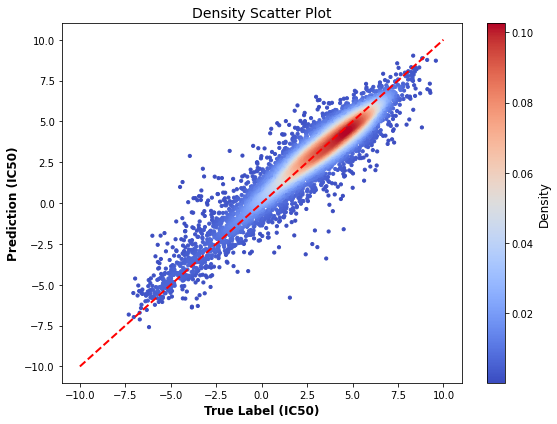

In [4]:
import numpy as np  # 添加这一行来导入 numpy 库

# 继续你的其他代码

# 读取数据
df = pd.read_csv("final_all_predictions_real_name.csv")

# ============ 图1: 密度散点图（True vs Predicted） ============ #
from scipy.stats import gaussian_kde

true = df["true_ic50"]
pred = df["predicted_ic50"]

# 计算密度
xy = np.vstack([true, pred])
z = gaussian_kde(xy)(xy)

# 排序（更好颜色渐变效果）
idx = z.argsort()
x, y, z = true.values[idx], pred.values[idx], z[idx]

# 创建图
plt.figure(figsize=(8, 6))
sc = plt.scatter(x, y, c=z, cmap='coolwarm', s=10)
plt.plot([-10, 10], [-10, 10], 'r--', lw=2)
plt.xlabel("True Label (IC50)", fontsize=12, weight='bold')
plt.ylabel("Prediction (IC50)", fontsize=12, weight='bold')
plt.title("Density Scatter Plot", fontsize=14)
cb = plt.colorbar(sc)
cb.set_label('Density', fontsize=12)
plt.tight_layout()
plt.savefig("picture/1.19density_scatter.tiff", dpi=400)
plt.show()


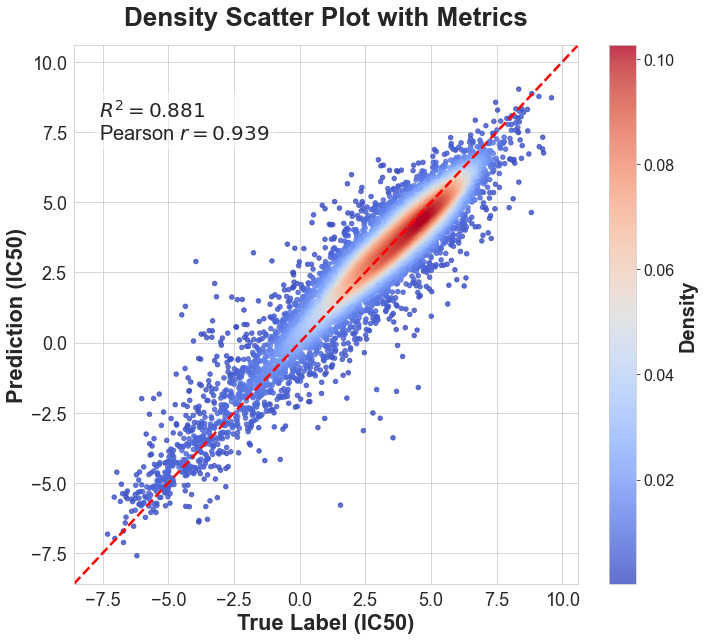

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde, pearsonr
from sklearn.metrics import r2_score

# 1. 准备数据
x = df['true_ic50']
y = df['predicted_ic50']

# 2. 计算统计指标
r, p_value = pearsonr(x, y)  # 计算 Pearson 相关系数
r2 = r2_score(x, y)          # 计算决定系数 R2

# 3. 计算点密度
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)
idx = z.argsort()
x_sorted, y_sorted, z_sorted = x.iloc[idx], y.iloc[idx], z[idx]

# 4. 创建图表
plt.figure(figsize=(10, 9))
sns.set_style("whitegrid")

# 绘制散点
sc = plt.scatter(x_sorted, y_sorted, c=z_sorted, cmap='coolwarm', s=20, alpha=0.8, edgecolor=None)

# 确定坐标轴范围（确保 1:1 比例）
limit_min = min(x.min(), y.min()) - 1
limit_max = max(x.max(), y.max()) + 1
plt.xlim(limit_min, limit_max)
plt.ylim(limit_min, limit_max)

# 绘制对角线 (y=x)
plt.plot([limit_min, limit_max], [limit_min, limit_max], 'r--', lw=2.5, label='y = x')

# --- 在图上标注统计信息 ---
# 这里的坐标 (0.05, 0.9) 表示在左上角附近，你可以根据数据位置调整
stats_text = f"$R^2 = {r2:.3f}$\nPearson $r = {r:.3f}$"
plt.text(0.05, 0.9, stats_text, 
         transform=plt.gca().transAxes, # 使用相对坐标
         fontsize=20, 
         verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

# --- 字体大小设置 ---
plt.xlabel("True Label (IC50)", fontsize=22, weight='bold')
plt.ylabel("Prediction (IC50)", fontsize=22, weight='bold')
plt.title("Density Scatter Plot with Metrics", fontsize=26, weight='bold', pad=20)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# 颜色条
cb = plt.colorbar(sc)
cb.set_label('Density', fontsize=20, weight='bold')
cb.ax.tick_params(labelsize=16)

plt.tight_layout()

# 保存
plt.savefig("picture/1.19_density_scatter_with_metrics.tiff", dpi=400, bbox_inches='tight')
plt.show()

选中药物 126565，敏感组 14 个，抗性组 14 个
差异上调基因数：26
进行 GO-BP 富集分析...
进行 KEGG 通路富集分析...


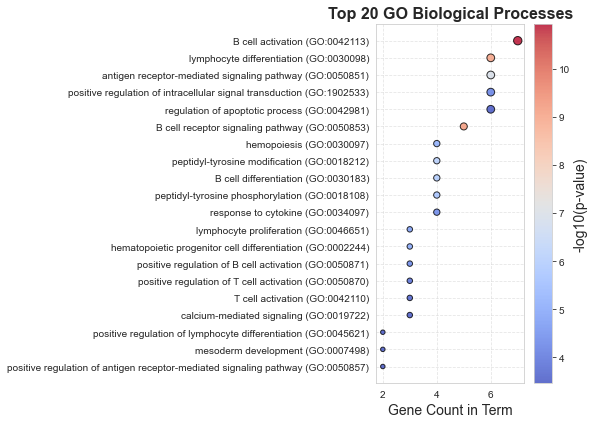

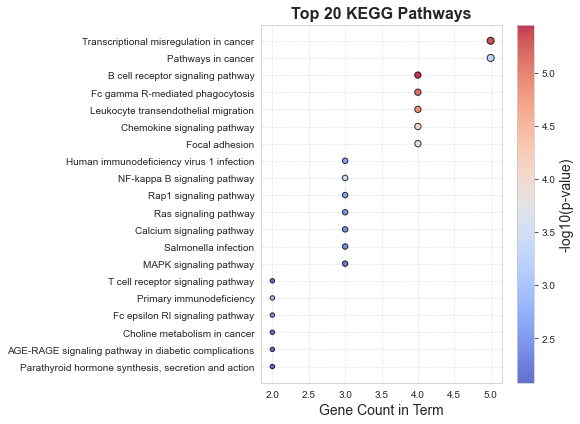

In [6]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind  # 修改为正确的函数名 
from gseapy import enrichr
import matplotlib.pyplot as plt

# ------------------ Step 1: 读取数据 ------------------
expr_df = pd.read_csv("geo_expression_cosmic.csv", index_col=0)
ic50_df = pd.read_csv("final_all_predictions_real_name.csv")

# ------------------ Step 2: 药物筛选和分组 ------------------
drug_id = 126565
drug_cells = ic50_df[ic50_df['drug'] == drug_id].copy()
drug_cells.sort_values("predicted_ic50", inplace=True)
n = int(len(drug_cells) * 0.3)
sensitive_cells = drug_cells.iloc[:n]["cell"].tolist()
resistant_cells = drug_cells.iloc[-n:]["cell"].tolist()
print(f"选中药物 {drug_id}，敏感组 {len(sensitive_cells)} 个，抗性组 {len(resistant_cells)} 个")

# ------------------ Step 3: 提取表达数据 ------------------
group1 = expr_df.loc[expr_df.index.intersection(sensitive_cells)]
group2 = expr_df.loc[expr_df.index.intersection(resistant_cells)]
common_genes = group1.columns.intersection(group2.columns)
group1 = group1[common_genes]
group2 = group2[common_genes]

# ------------------ Step 4: 差异表达分析 ------------------
pvals = []
log2fc = []

for gene in common_genes:
    g1_vals = group1[gene].dropna()
    g2_vals = group2[gene].dropna()
    if len(g1_vals) > 1 and len(g2_vals) > 1:
        stat, pval = ttest_ind(g1_vals, g2_vals, equal_var=False)
        pvals.append(pval)
        log2fc.append(np.log2(g1_vals.mean() + 1e-6) - np.log2(g2_vals.mean() + 1e-6))
    else:
        pvals.append(1.0)
        log2fc.append(0)

de_df = pd.DataFrame({
    "gene": common_genes,
    "pvalue": pvals,
    "log2fc": log2fc
})
de_df.sort_values("pvalue", inplace=True)

# ------------------ Step 5: 筛选显著上调基因 ------------------
sig_genes = de_df[(de_df["pvalue"] < 0.05) & (de_df["log2fc"] > 1)]
gene_list = sig_genes["gene"].tolist()
print(f"差异上调基因数：{len(gene_list)}")

# ------------------ Step 6: 富集分析 ------------------
print("进行 GO-BP 富集分析...")
go_results = enrichr(gene_list=gene_list,
                     gene_sets='GO_Biological_Process_2021',
                     organism='Human',
                     outdir=None,
                     cutoff=0.5)

print("进行 KEGG 通路富集分析...")
kegg_results = enrichr(gene_list=gene_list,
                       gene_sets='KEGG_2021_Human',
                       organism='Human',
                       outdir=None,
                       cutoff=0.5)

# ------------------ Step 7: 自定义美化绘图函数 ------------------
def beautiful_dotplot(df, title, output_file, top_n=20):
    df = df.head(top_n).copy()
    df['Gene_Count'] = df['Overlap'].apply(lambda x: int(x.split('/')[0]))
    df['-log10(pval)'] = -np.log10(df['P-value'])
    df.sort_values('Gene_Count', ascending=True, inplace=True)

    plt.figure(figsize=(8, 6))
    sc = plt.scatter(
        x=df['Gene_Count'],
        y=df['Term'],
        c=df['-log10(pval)'],
        s=df['Gene_Count'] * 10,
        cmap='coolwarm',
        edgecolors='black',
        alpha=0.8
    )

    cbar = plt.colorbar(sc)
    cbar.set_label('-log10(p-value)', fontsize=14)

    plt.xlabel('Gene Count in Term', fontsize=14)
    plt.ylabel('')
    plt.title(title, fontsize=16, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(output_file, dpi=400)
    plt.show()

# ------------------ Step 8: 绘图 ------------------
beautiful_dotplot(go_results.res2d, 'Top 20 GO Biological Processes', 'picture/1.19go_biological_process_enrichment.tiff')
beautiful_dotplot(kegg_results.res2d, 'Top 20 KEGG Pathways', 'picture/1.19kegg_pathway_enrichment.tiff')


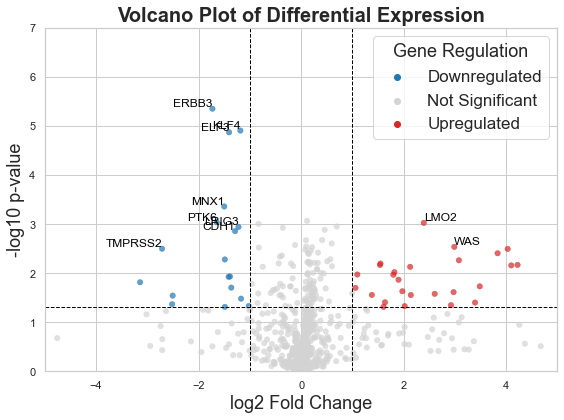

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 计算显著性标注
de_df['-log10_pvalue'] = -np.log10(de_df['pvalue'])
de_df['significance'] = 'Not Significant'
de_df.loc[(de_df['pvalue'] < 0.05) & (de_df['log2fc'] > 1), 'significance'] = 'Upregulated'
de_df.loc[(de_df['pvalue'] < 0.05) & (de_df['log2fc'] < -1), 'significance'] = 'Downregulated'

# 选出前10显著基因用于标注
top_genes = de_df[de_df['significance'] != 'Not Significant'].sort_values('pvalue').head(10)

# 画图
plt.figure(figsize=(8, 6))
sns.set(style="whitegrid")

# 火山图散点图
sns.scatterplot(
    data=de_df, x='log2fc', y='-log10_pvalue', hue='significance',
    palette={
        'Upregulated': '#d62728',      # 红色
        'Downregulated': '#1f77b4',    # 蓝色
        'Not Significant': 'lightgray' # 灰色
    },
    alpha=0.7, s=30, edgecolor=None
)

# 添加阈值线
plt.axvline(x=1, color='black', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='black', linestyle='--', linewidth=1)
plt.axhline(y=-np.log10(0.05), color='black', linestyle='--', linewidth=1)

# 标注top显著基因
for _, row in top_genes.iterrows():
    plt.text(
        row['log2fc'], row['-log10_pvalue'], row['gene'],
        fontsize=12,
        ha='right' if row['log2fc'] < 0 else 'left',
        va='bottom', color='black'
    )

# 图像美化
plt.title('Volcano Plot of Differential Expression', fontsize=20, weight='bold')
plt.xlabel('log2 Fold Change', fontsize=18)
plt.ylabel('-log10 p-value', fontsize=18)
plt.legend(title='Gene Regulation', loc='upper right', fontsize=17, title_fontsize=18)
plt.xlim(-5, 5)
plt.ylim(0, np.ceil(de_df['-log10_pvalue'].max()) + 1)
plt.tight_layout()

# 保存并显示
plt.savefig('picture/1.19volcano_plot_final.tiff', dpi=400)
plt.show()
